In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("loan_approval_data.csv")
df = df.dropna(subset=["Loan_Approved"]).reset_index(drop=True)   # never impute the target


In [3]:
df.head()
df.info()
df.isnull().sum()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 950 entries, 0 to 949
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        902 non-null    float64
 1   Applicant_Income    902 non-null    float64
 2   Coapplicant_Income  902 non-null    float64
 3   Employment_Status   906 non-null    str    
 4   Age                 902 non-null    float64
 5   Marital_Status      902 non-null    str    
 6   Dependents          903 non-null    float64
 7   Credit_Score        902 non-null    float64
 8   Existing_Loans      901 non-null    float64
 9   DTI_Ratio           903 non-null    float64
 10  Savings             901 non-null    float64
 11  Collateral_Value    901 non-null    float64
 12  Loan_Amount         903 non-null    float64
 13  Loan_Term           902 non-null    float64
 14  Loan_Purpose        902 non-null    str    
 15  Property_Area       901 non-null    str    
 16  Education_Level    

,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term
count,902.000000,902.000000,902.000000,902.000000,903.000000,902.000000,901.000000,903.000000,901.000000,901.000000,903.000000,902.000000
mean,498.529933,10847.016630,5061.607539,40.044346,1.460687,675.111973,1.948946,0.347187,9966.298557,24701.875694,20455.895903,48.000000
std,290.651274,5064.213641,2937.413855,11.194488,1.103489,71.327228,1.406197,0.144522,5859.624544,14328.907796,11511.440627,24.258321
min,1.000000,2009.000000,1.000000,21.000000,0.000000,550.000000,0.000000,0.100000,73.000000,36.000000,1015.000000,12.000000
25%,243.250000,6742.000000,2469.750000,31.000000,1.000000,616.000000,1.000000,0.220000,4761.000000,12634.000000,9772.500000,24.000000
50%,497.500000,10452.500000,5143.000000,40.000000,1.000000,677.000000,2.000000,0.340000,9910.000000,24059.000000,21282.000000,48.000000
75%,752.750000,15174.250000,7589.750000,49.000000,2.000000,735.000000,3.000000,0.480000,15052.000000,36843.000000,30138.500000,72.000000
max,1000.000000,19988.000000,9996.000000,59.000000,3.000000,799.000000,4.000000,0.600000,19996.000000,49954.000000,39995.000000,84.000000


# EDA - exploratory data analysis

Done on the raw data. EDA only looks at the data; nothing is fitted or imputed here.

Text(0.5, 1.0, 'Is Loan approved or not?')

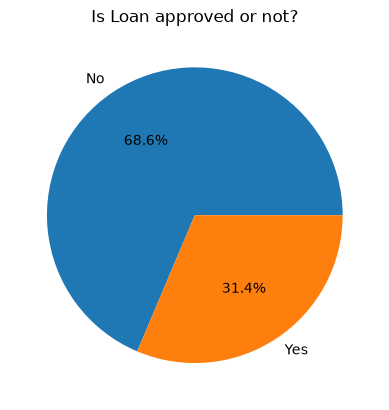

In [4]:
# how balanced our classes are?

classes_count = df["Loan_Approved"].value_counts()

plt.pie(classes_count, labels=classes_count.index, autopct="%1.1f%%")
plt.title("Is Loan approved or not?")

[Text(0, 0, '638'), Text(0, 0, '265')]

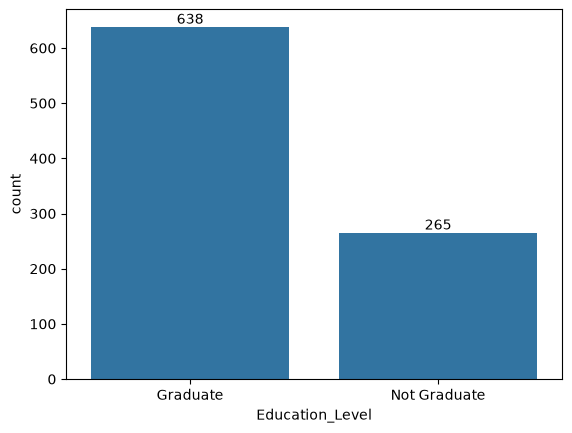

In [5]:
# analyze categories

# gender_cnt = df["Gender"].value_counts()
# ax = sns.barplot(gender_cnt)
# ax.bar_label(ax.containers[0])

edu_cnt = df["Education_Level"].value_counts()
ax = sns.barplot(edu_cnt)
ax.bar_label(ax.containers[0])

<Axes: xlabel='Applicant_Income', ylabel='Count'>

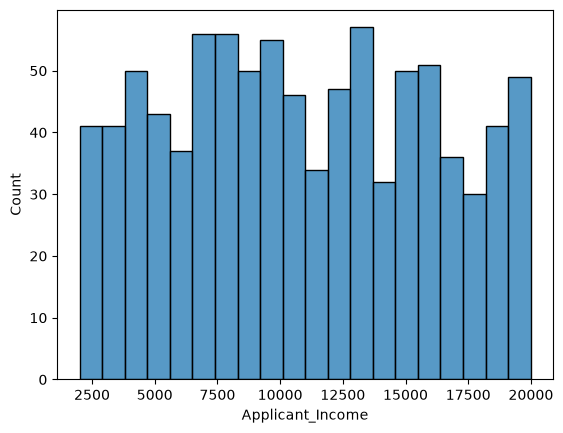

In [6]:
# analyze income

sns.histplot(
    data = df,
    x = "Applicant_Income",
    bins=20
)

<Axes: xlabel='Coapplicant_Income', ylabel='Count'>

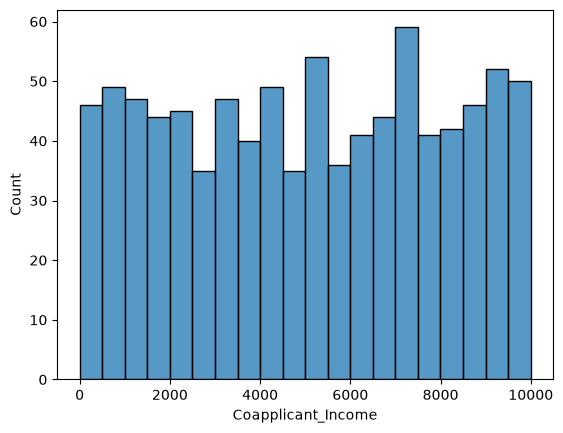

In [7]:
sns.histplot(
    data = df,
    x = "Coapplicant_Income",
    bins=20
)

<Axes: xlabel='Loan_Approved', ylabel='Applicant_Income'>

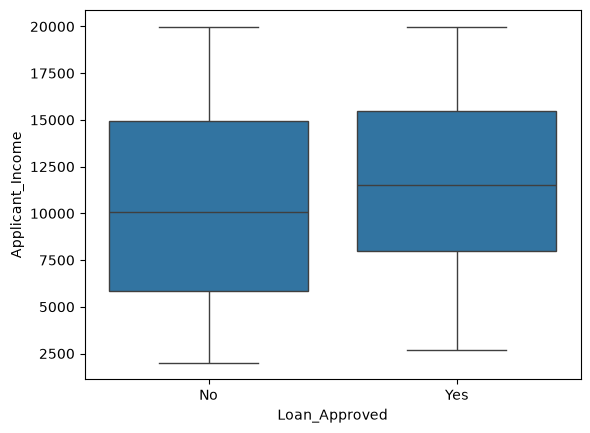

In [8]:
# outliers - box plots

sns.boxplot(
    data=df,
    x="Loan_Approved",
    y="Applicant_Income"
)

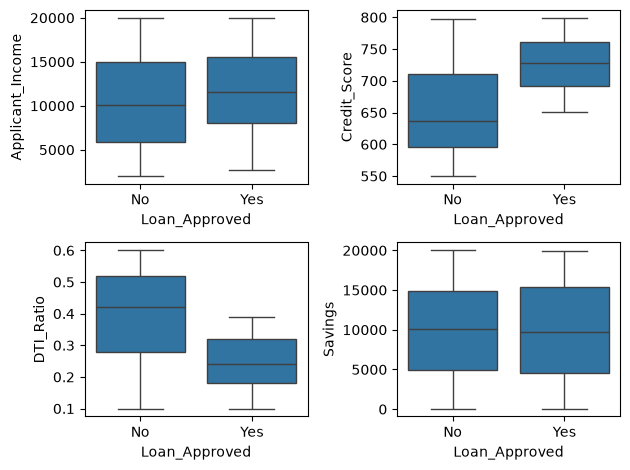

In [9]:
fig, axes = plt.subplots(2, 2)

sns.boxplot(ax=axes[0, 0], data=df, x="Loan_Approved",y="Applicant_Income")
sns.boxplot(ax=axes[0, 1], data=df, x="Loan_Approved",y="Credit_Score")
sns.boxplot(ax=axes[1, 0], data=df, x="Loan_Approved",y="DTI_Ratio")
sns.boxplot(ax=axes[1, 1], data=df, x="Loan_Approved",y="Savings")

plt.tight_layout()

<Axes: xlabel='Credit_Score', ylabel='Count'>

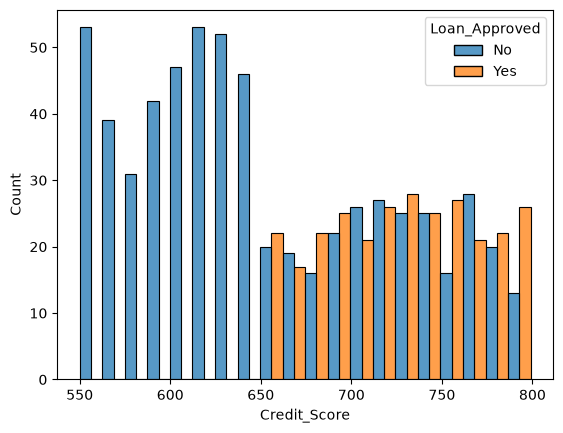

In [10]:
# Credit Score with Loan Approved

sns.histplot(
    data=df,
    x="Credit_Score",
    hue="Loan_Approved",
    bins=20,
    multiple="dodge"
)

<Axes: xlabel='Applicant_Income', ylabel='Count'>

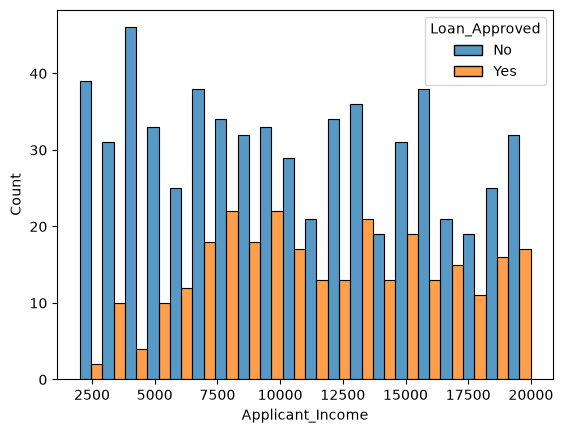

In [11]:
sns.histplot(
    data=df,
    x="Applicant_Income",
    hue="Loan_Approved",
    bins=20,
    multiple="dodge"
)

# Prepare features and target

These steps are fixed rules that learn nothing from the data, so they are safe to do before the split.

`Applicant_ID` is just an identifier. `Gender` is removed because it should not influence a loan decision.

In [12]:
df = df.drop(columns=["Applicant_ID", "Gender"])

X = df.drop(columns=["Loan_Approved"])
y = df["Loan_Approved"].map({"No": 0, "Yes": 1}).astype(int)   # fails loudly if an unexpected label exists

# Train / Validation / Test split

60% train, 20% validation, 20% test.

The split happens **before** anything is learned from the data. Imputers, the encoder and the scaler are fitted on the training set only, then applied to validation and test.

In [13]:
# 80% development data, 20% final test data
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# development data -> 60% train, 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.25,
    random_state=42,
    stratify=y_train_full
)

X_train, X_val, X_test = X_train.copy(), X_val.copy(), X_test.copy()
print(X_train.shape, X_val.shape, X_test.shape)

(570, 17) (190, 17) (190, 17)


# Handle Missing Values (fit on train only)

Median for continuous columns, most frequent value for count-like and categorical columns. This avoids impossible values such as 1.47 dependents.

In [14]:
from sklearn.impute import SimpleImputer

cont_cols = ["Applicant_Income", "Coapplicant_Income", "Age", "Credit_Score",
             "DTI_Ratio", "Savings", "Collateral_Value", "Loan_Amount"]
discrete_cols = ["Dependents", "Existing_Loans", "Loan_Term"]
cat_cols = ["Employment_Status", "Marital_Status", "Loan_Purpose",
            "Property_Area", "Education_Level", "Employer_Category"]

imputers = [
    (SimpleImputer(strategy="median"), cont_cols),
    (SimpleImputer(strategy="most_frequent"), discrete_cols),
    (SimpleImputer(strategy="most_frequent"), cat_cols),
]

for imp, cols in imputers:
    X_train[cols] = imp.fit_transform(X_train[cols])   # learn from train only
    X_val[cols] = imp.transform(X_val[cols])
    X_test[cols] = imp.transform(X_test[cols])

In [15]:
print(X_train.isnull().sum().sum(), X_val.isnull().sum().sum(), X_test.isnull().sum().sum())

0 0 0


# Encoding (fit on train only)

In [16]:
from sklearn.preprocessing import OneHotEncoder

# Education_Level has two ordered levels -> fixed mapping, nothing to fit
edu_map = {"Not Graduate": 0, "Graduate": 1}
for frame in (X_train, X_val, X_test):
    frame["Education_Level"] = frame["Education_Level"].map(edu_map)

assert X_train["Education_Level"].notna().all()

# One-hot encode the remaining categoricals; categories are learned from train only
ohe_cols = ["Employment_Status", "Marital_Status", "Loan_Purpose", "Property_Area", "Employer_Category"]
ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")
ohe.fit(X_train[ohe_cols])

def encode(frame):
    encoded = pd.DataFrame(
        ohe.transform(frame[ohe_cols]),
        columns=ohe.get_feature_names_out(ohe_cols),
        index=frame.index
    )
    return pd.concat([frame.drop(columns=ohe_cols), encoded], axis=1)

X_train, X_val, X_test = encode(X_train), encode(X_val), encode(X_test)
X_train.info()

<class 'pandas.DataFrame'>
Index: 570 entries, 622 to 626
Data columns (total 26 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Applicant_Income                 570 non-null    float64
 1   Coapplicant_Income               570 non-null    float64
 2   Age                              570 non-null    float64
 3   Dependents                       570 non-null    float64
 4   Credit_Score                     570 non-null    float64
 5   Existing_Loans                   570 non-null    float64
 6   DTI_Ratio                        570 non-null    float64
 7   Savings                          570 non-null    float64
 8   Collateral_Value                 570 non-null    float64
 9   Loan_Amount                      570 non-null    float64
 10  Loan_Term                        570 non-null    float64
 11  Education_Level                  570 non-null    int64  
 12  Employment_Status_Salaried       570

# Correlation Heatmap (training data only)

<Axes: >

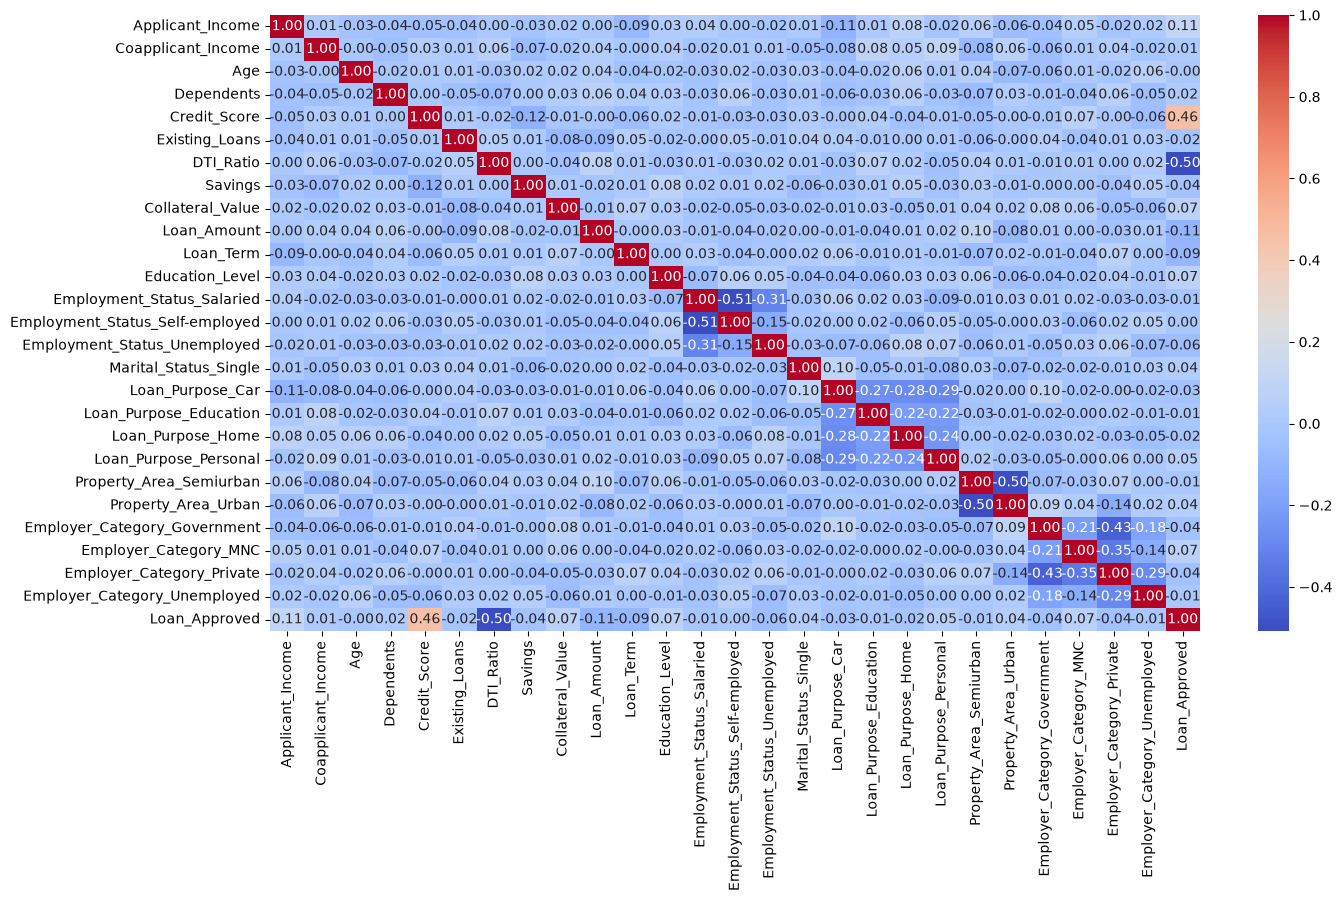

In [17]:
train_df = X_train.join(y_train)
corr_matrix = train_df.corr()

plt.figure(figsize=(15, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

In [18]:
corr_matrix["Loan_Approved"].sort_values(ascending=False)

Loan_Approved                      1.000000
Credit_Score                       0.455039
Applicant_Income                   0.108836
Education_Level                    0.073038
Collateral_Value                   0.069249
Employer_Category_MNC              0.065264
Loan_Purpose_Personal              0.047872
Property_Area_Urban                0.043547
Marital_Status_Single              0.036422
Dependents                         0.019943
Coapplicant_Income                 0.010584
Employment_Status_Self-employed    0.000827
Age                               -0.002670
Property_Area_Semiurban           -0.006340
Employer_Category_Unemployed      -0.012848
Loan_Purpose_Education            -0.013008
Employment_Status_Salaried        -0.014665
Loan_Purpose_Home                 -0.023404
Existing_Loans                    -0.023560
Loan_Purpose_Car                  -0.033794
Savings                           -0.035761
Employer_Category_Private         -0.041422
Employer_Category_Government    

# Feature Scaling (fit on train only)

In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Train & Evaluate Models (validation set)

In [20]:
# Logistic regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
log_model = LogisticRegression()
log_model.fit(X_train_scaled, y_train)

y_pred = log_model.predict(X_val_scaled)

# Evaluation
print("Logistic Regression Model")
print("Precision: ", precision_score(y_val, y_pred))
print("Recall: ", recall_score(y_val, y_pred))
print("F1 score: ", f1_score(y_val, y_pred))
print("Accuracy: ", accuracy_score(y_val, y_pred))
print("CM: ", confusion_matrix(y_val, y_pred))

Logistic Regression Model
Precision:  0.75
Recall:  0.75
F1 score:  0.75
Accuracy:  0.8421052631578947
CM:  [[115  15]
 [ 15  45]]


In [21]:
# KNN
from sklearn.neighbors import KNeighborsClassifier
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

y_pred = knn_model.predict(X_val_scaled)

# Evaluation
print("KNN Model")
print("Precision: ", precision_score(y_val, y_pred))
print("Recall: ", recall_score(y_val, y_pred))
print("F1 score: ", f1_score(y_val, y_pred))
print("Accuracy: ", accuracy_score(y_val, y_pred))
print("CM: ", confusion_matrix(y_val, y_pred))

KNN Model
Precision:  0.4666666666666667
Recall:  0.35
F1 score:  0.4
Accuracy:  0.6684210526315789
CM:  [[106  24]
 [ 39  21]]


In [22]:
# Naive Bayes
from sklearn.naive_bayes import GaussianNB
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)

y_pred = nb_model.predict(X_val_scaled)

# Evaluation
print("Naive Bayes Model")
print("Precision: ", precision_score(y_val, y_pred))
print("Recall: ", recall_score(y_val, y_pred))
print("F1 score: ", f1_score(y_val, y_pred))
print("Accuracy: ", accuracy_score(y_val, y_pred))
print("CM: ", confusion_matrix(y_val, y_pred))

Naive Bayes Model
Precision:  0.8076923076923077
Recall:  0.7
F1 score:  0.75
Accuracy:  0.8526315789473684
CM:  [[120  10]
 [ 18  42]]


## Best Model on the basis of Precision => Naive Bayes (validation set)

# Feature Engineering

In [23]:
# Row-wise transforms learn nothing from the data, so they can be applied to every split.
# The scaler is re-fitted on the new training features only.
X_train_fe, X_val_fe, X_test_fe = X_train.copy(), X_val.copy(), X_test.copy()

for frame in (X_train_fe, X_val_fe, X_test_fe):
    frame["DTI_Ratio_sq"] = frame["DTI_Ratio"] ** 2
    frame["Credit_Score_sq"] = frame["Credit_Score"] ** 2
    frame.drop(columns=["Credit_Score", "DTI_Ratio"], inplace=True)

scaler_fe = StandardScaler()

X_train_fe_scaled = scaler_fe.fit_transform(X_train_fe)
X_val_fe_scaled = scaler_fe.transform(X_val_fe)
X_test_fe_scaled = scaler_fe.transform(X_test_fe)

C:\Users\rajpa\AppData\Local\Temp\ipykernel_11928\475694170.py:8: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  frame.drop(columns=["Credit_Score", "DTI_Ratio"], inplace=True)


In [24]:
# Logistic regression (engineered features)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
log_model_fe = LogisticRegression()
log_model_fe.fit(X_train_fe_scaled, y_train)

y_pred = log_model_fe.predict(X_val_fe_scaled)

# Evaluation
print("Logistic Regression Model (FE)")
print("Precision: ", precision_score(y_val, y_pred))
print("Recall: ", recall_score(y_val, y_pred))
print("F1 score: ", f1_score(y_val, y_pred))
print("Accuracy: ", accuracy_score(y_val, y_pred))
print("CM: ", confusion_matrix(y_val, y_pred))

Logistic Regression Model (FE)
Precision:  0.7619047619047619
Recall:  0.8
F1 score:  0.7804878048780488
Accuracy:  0.8578947368421053
CM:  [[115  15]
 [ 12  48]]


In [25]:
# KNN (engineered features)
from sklearn.neighbors import KNeighborsClassifier
knn_model_fe = KNeighborsClassifier(n_neighbors=5)
knn_model_fe.fit(X_train_fe_scaled, y_train)

y_pred = knn_model_fe.predict(X_val_fe_scaled)

# Evaluation
print("KNN Model (FE)")
print("Precision: ", precision_score(y_val, y_pred))
print("Recall: ", recall_score(y_val, y_pred))
print("F1 score: ", f1_score(y_val, y_pred))
print("Accuracy: ", accuracy_score(y_val, y_pred))
print("CM: ", confusion_matrix(y_val, y_pred))

KNN Model (FE)
Precision:  0.5106382978723404
Recall:  0.4
F1 score:  0.4485981308411215
Accuracy:  0.6894736842105263
CM:  [[107  23]
 [ 36  24]]


In [26]:
# Naive Bayes (engineered features)
from sklearn.naive_bayes import GaussianNB
nb_model_fe = GaussianNB()
nb_model_fe.fit(X_train_fe_scaled, y_train)

y_pred = nb_model_fe.predict(X_val_fe_scaled)

# Evaluation
print("Naive Bayes Model (FE)")
print("Precision: ", precision_score(y_val, y_pred))
print("Recall: ", recall_score(y_val, y_pred))
print("F1 score: ", f1_score(y_val, y_pred))
print("Accuracy: ", accuracy_score(y_val, y_pred))
print("CM: ", confusion_matrix(y_val, y_pred))

Naive Bayes Model (FE)
Precision:  0.8
Recall:  0.7333333333333333
F1 score:  0.7652173913043478
Accuracy:  0.8578947368421053
CM:  [[119  11]
 [ 16  44]]


# Final check on the test set

Choose the model from the **validation** results above, then evaluate it on the test set **once**. Do not go back and tune after seeing this result.

In [27]:
# Set final_model to whichever model won on validation (nb_model_fe, log_model_fe, ...)
final_model = nb_model_fe

y_pred = final_model.predict(X_test_fe_scaled)

print("Final model on TEST set")
print("Precision: ", precision_score(y_test, y_pred))
print("Recall: ", recall_score(y_test, y_pred))
print("F1 score: ", f1_score(y_test, y_pred))
print("Accuracy: ", accuracy_score(y_test, y_pred))
print("CM: ", confusion_matrix(y_test, y_pred))

Final model on TEST set
Precision:  0.8181818181818182
Recall:  0.75
F1 score:  0.782608695652174
Accuracy:  0.868421052631579
CM:  [[120  10]
 [ 15  45]]
